In [1]:

import pandas as pd
import re

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load dataset
df = pd.read_csv(r"C:\Users\Hp\Downloads\sql_injection_dataset.csv")

# 2. Extract features from SQL queries
def extract_features(query):
    q = query.lower()

    return [
        len(q),
        len(re.findall(r"\b(select|insert|update|delete|drop|union)\b", q)),
        sum(q.count(c) for c in ["'", ";", "-", "#", "/"]),
        int(bool(re.search(r"--|#|/\*|\*/", q))),
        int("union" in q),
        int(bool(re.search(r"\bdrop\b", q))),
        int(bool(re.search(r"\bor\b", q))),
        int(bool(re.search(r"1\s*=\s*1|'1'\s*=\s*'1'", q))),
        int(bool(re.search(r"\b(exec|shutdown|sleep)\b", q)))
    ]

# 3. Prepare features and labels
X = pd.DataFrame(
    df["query"].apply(extract_features).tolist(),
    columns=[
        "Length", "SQL_Keywords", "Special_Characters",
        "Has_Comment", "Has_Union", "Has_Drop",
        "Has_OR", "Tautology", "Dangerous_Keyword"
    ]
)

y = df["label"]

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25,
    random_state=42, stratify=y
)

# 5. Train Decision Tree
model = DecisionTreeClassifier(
    max_depth=5, random_state=42
)

model.fit(X_train, y_train)

# 6. Predict test results
y_pred = model.predict(X_test)

# 7. Display accuracy
print("Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 8. Test new SQL queries
new_queries = [
    "SELECT name FROM users WHERE id = 10",
    "' OR 1=1 --",
    "SELECT * FROM users UNION SELECT password FROM accounts",
    "SELECT email FROM customers WHERE city = 'Mysore'"
]

new_features = pd.DataFrame(
    [extract_features(q) for q in new_queries],
    columns=X.columns
)

predictions = model.predict(new_features)

# 9. Display predictions
print("\nSQL Injection Detection Results:")

for query, prediction in zip(new_queries, predictions):
    result = "Malicious" if prediction == 1 else "Normal"
    print("\nQuery:", query)
    print("Prediction:", result)


Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         7

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15

Confusion Matrix:
[[8 0]
 [0 7]]

SQL Injection Detection Results:

Query: SELECT name FROM users WHERE id = 10
Prediction: Normal

Query: ' OR 1=1 --
Prediction: Malicious

Query: SELECT * FROM users UNION SELECT password FROM accounts
Prediction: Malicious

Query: SELECT email FROM customers WHERE city = 'Mysore'
Prediction: Normal


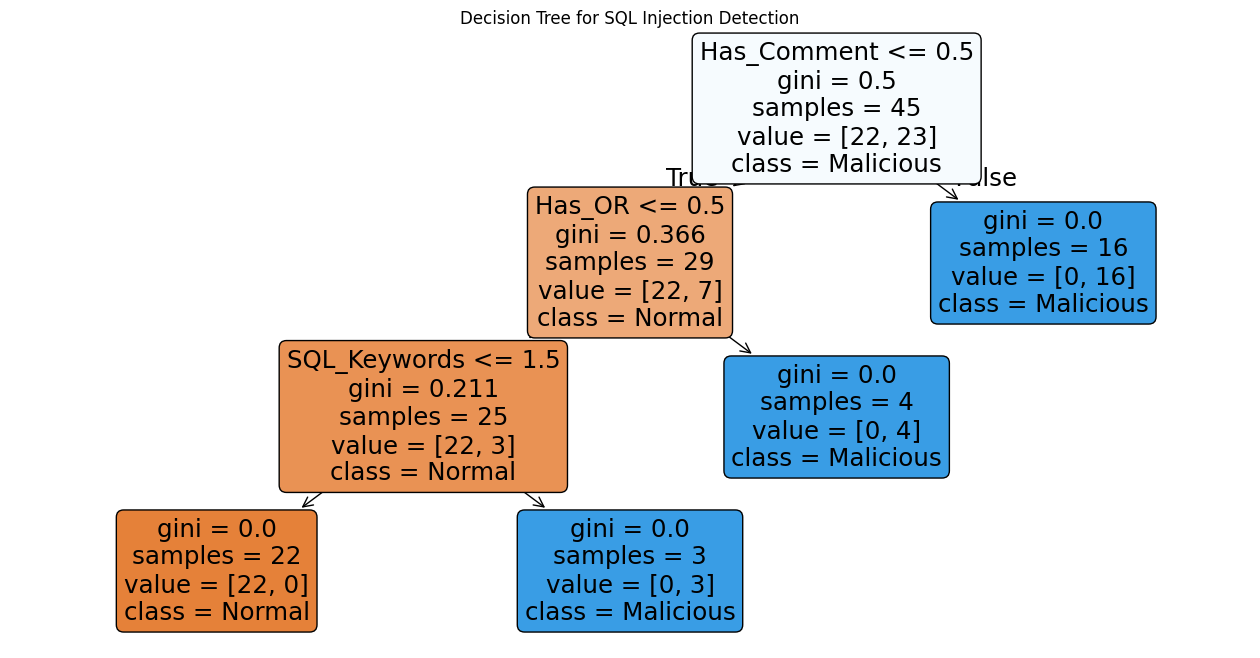

In [2]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Normal', 'Malicious'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree for SQL Injection Detection")
plt.show()